# Imports

In [73]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [74]:
def show_rgb(img, title="Image"):
    if img.ndim == 3:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap='gray' if img.ndim == 2 else None)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Question 1

In [75]:
def intensity_transform(im, breakpoints):
    """
    Apply piecewise-linear intensity transformation.

    breakpoints:
        Nx2 array
        first column  = input intensity
        second column = output intensity
    """

    breakpoints = np.asarray(breakpoints, dtype=np.float32)

    x = breakpoints[:, 0]
    y = breakpoints[:, 1]

    transformed = np.interp(im.astype(np.float32), x, y)

    return np.clip(transformed, 0, 255).astype(np.uint8)

In [76]:
def plot_transformed(img, breakpoints, label=None):
    """
    Plot the original and transformed images along with the transformation function.
    """

    transformed = intensity_transform(img, breakpoints)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(transformed, cmap='gray')
    if label is not None:
        plt.title(f"{label}")
    else:
        plt.title("Transformed Image")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    x = breakpoints[:, 0]
    y = breakpoints[:, 1]
    plt.plot(x, y, marker='o')
    plt.title("Transformation Function")
    plt.xlabel("Input Intensity")
    plt.ylabel("Output Intensity")
    plt.grid()

    plt.tight_layout()
    plt.show()

In [77]:
emma = cv.imread("Images/emma.jpg", cv.IMREAD_GRAYSCALE)



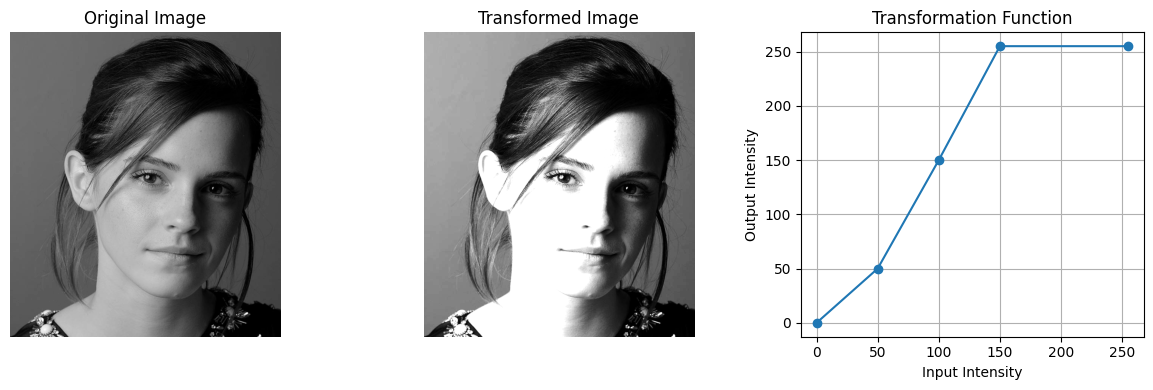

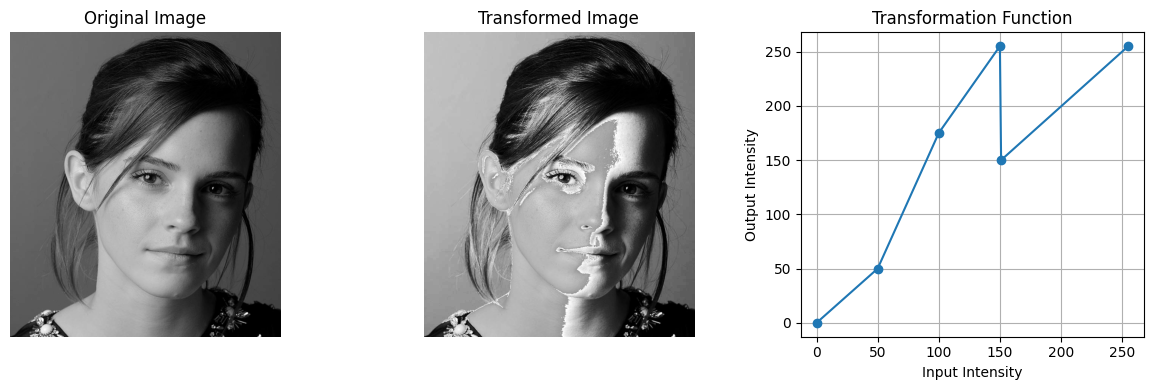

In [78]:
breakpoints1 = np.array([
    [0,   0],
    [50,  50],
    [100, 150],
    [150, 255],
    [255, 255]
])
breakpoints2 = np.array([
    [0, 0],
    [50,50],
    [100,175],
    [150,255],
    [151,150],
    [255,255]
])

plot_transformed(emma, breakpoints1)
plot_transformed(emma, breakpoints2)

[[ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 ...
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]]


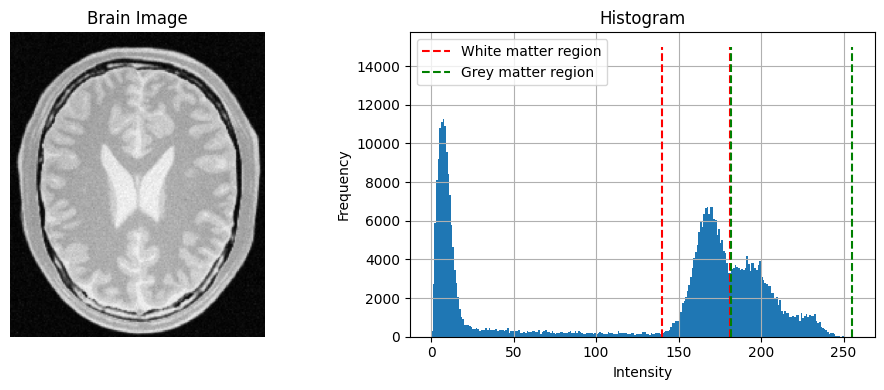

In [79]:
brain = cv.imread("Images/brain.png", cv.IMREAD_GRAYSCALE)
print(brain)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(brain, cmap='gray')
plt.title("Brain Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(brain.ravel(), bins=256, range=(0, 256))
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.grid(True)

ax1 = 140
plt.plot([ax1, ax1], [0, 15000], color='red', linestyle='--', label=f'White matter region')
ax2 = 181
plt.plot([ax2, ax2], [0, 15000], color='red', linestyle='--')
ax1 = 182
plt.plot([ax1, ax1], [0, 15000], color='green', linestyle='--', label=f'Grey matter region')
ax2 = 255
plt.plot([ax2, ax2], [0, 15000], color='green', linestyle='--')

plt.tight_layout()
plt.legend()
plt.show()

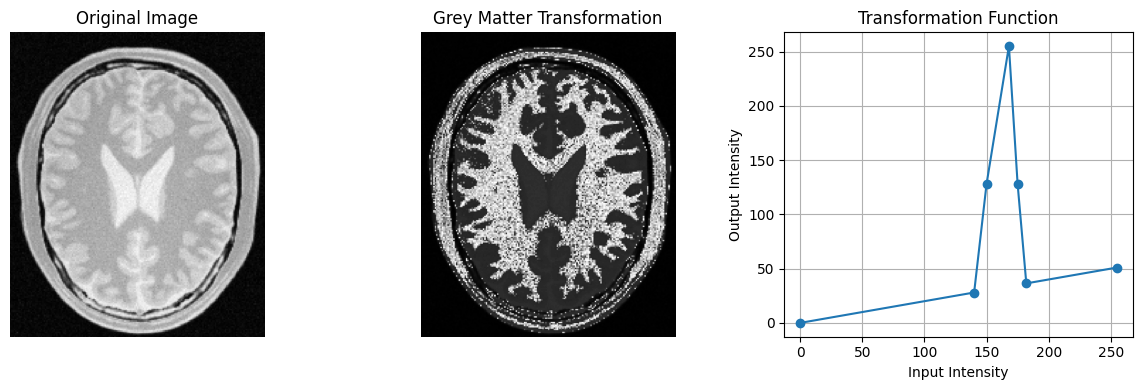

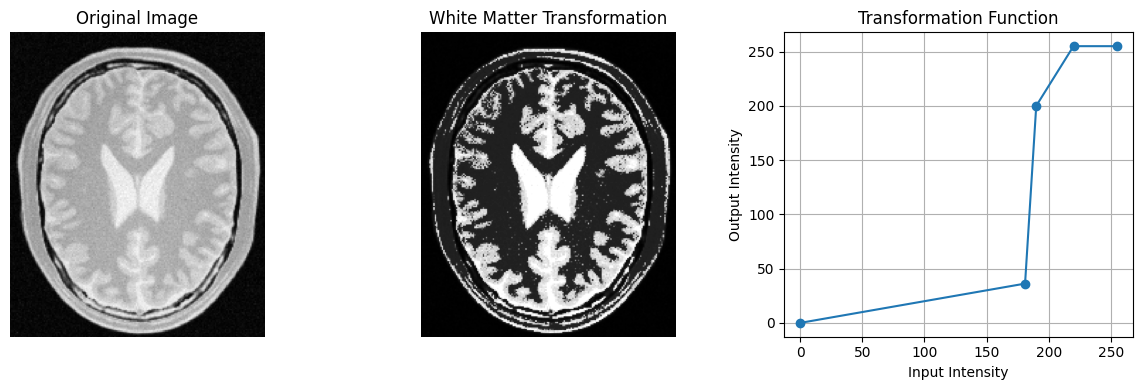

In [80]:
breakpoints_grey = np.array([
    [0, 0],
    [140, 140*0.2],
    [150, 128],
    [168, 255],
    [175, 128],
    [182, 182*0.2],
    [255, 255*0.2]
])
breakpoints_white = np.array([
    [0, 0],
    [181, 181*0.2],
    [190, 200],
    [220, 255],
    [255, 255]
])

plot_transformed(brain, breakpoints_grey, label="Grey Matter Transformation")
plot_transformed(brain, breakpoints_white, label="White Matter Transformation")

In [94]:
img = cv.imread("Images/q3.png")

lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)

L, a, b = cv.split(lab)

gamma = 1.5

L_norm = L.astype(np.float32) / 255.0
L_gamma = 255 * (L_norm ** gamma)
L_gamma = np.clip(L_gamma, 0, 255).astype(np.uint8)

lab_corrected = cv.merge([L_gamma, a, b])

corrected = cv.cvtColor(lab_corrected, cv.COLOR_LAB2RGB)

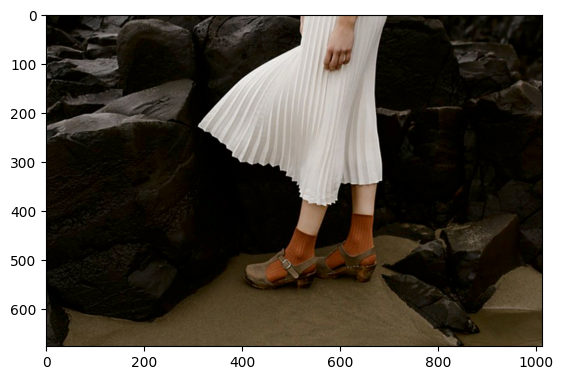

In [95]:
plt.imshow(corrected)